# E12-H59 - Structure threshold cross-article transfer

**Author** - kj &nbsp;|&nbsp; **Execution model** - opus &nbsp;|&nbsp; **Type** - read-only probe (verdict layer)

`STRUCTURE_THRESHOLD = 0.90` (`src/docdistance/distance.py:40`) is the closeness cutoff for the
`similar order` / `not similar order` verdict. It was placed in-sample on the **ibm** scramble ladder alone.
The byte-identical k-swap fixture lands rung-2 about 1.5 closeness points apart across the two articles
(ibm `1 - 0.15158/sqrt(2)`, wergeland `1 - 0.13004/sqrt(2)`), so the same physical perturbation depth can
land on opposite sides of a fixed boundary.

**Approach**

1. **Kill-gate** - closeness arithmetic on `reports/E11-structure-sota-decision.json` `.scramble`: does the
   cross-article verdict flip at 0.90 exist at all
2. **Rebuild the un-reordered pairs** - the E11 report stores diffuse medians only, so re-encode the fixture
   documents and recompute per-pair `opw_gap` (H55) through the E11 notebook path, on CPU
3. **Reproduction check** - the recomputed medians must land on the E11 report's stored medians
4. **Sweep** - structural threshold 0.85 to 0.99 at 0.005 steps over both articles' H55 ladders plus every
   un-reordered diffuse and paraphrase pair; count mis-sided rungs and falsely-flagged un-reordered pairs
   per article; publish the cross-article safe band or prove it empty
5. **Guardrails** - `V` counted on the default path, default-path `smd` / `order_gap` bit-identity measured
   by `np.array_equal` and a byte diff, metric property stated

Nothing in the distance changes here. The sweep reads the verdict layer only.

## Environment

No GPU: the workstation's cards are held by foreign jobs and the campaign primer pins this phase to CPU.
`CUDA_VISIBLE_DEVICES` is emptied before torch is imported so the torch encoder cannot claim a device, and
`DOCDISTANCE_HOME` is pinned to the repo root so the offline model config resolves when nbconvert runs with
its cwd at the notebook directory. The optimal-transport math is CPU numpy in every case.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU pin - GPUs are held by foreign jobs (campaign primer)
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
# nbconvert runs with cwd at the notebook directory; docdistance.json lives at the repo root
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import warnings

warnings.filterwarnings("ignore")

import torch

DEVICE = "cpu"
print(f"torch {torch.__version__} | cuda visible {torch.cuda.is_available()} | device {DEVICE}")

torch 2.12.0+cu130 | cuda visible False | device cpu


## Imports

One cell, grouped standard library / third party / project. The E11 mechanism (`opw_gap`) is re-implemented
below from the E11 notebook rather than imported, so the ladder rebuild is the E11 path verbatim; the shipped
`docdistance` functions are imported alongside for the guardrail measurements.

In [2]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rich.console import Console
from rich.table import Table

import ot
import docdistance
from docdistance import DocDistance
from docdistance.distance import (
    DEFAULT_THRESHOLD,
    SMD_MAX,
    STRUCTURE_THRESHOLD,
    closeness,
    cost_matrix,
    smd,
)
from docdistance.encoders import load_encoder

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print(f"imports ready | docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__}")

imports ready | docdistance 1.1.5 | POT 0.9.7.post1 | numpy 2.4.6


## Reproducibility

One seed. The probe is deterministic anyway - no sampling enters the sweep - but the encoder and the
optimal-transport solvers are seeded for form.

In [3]:
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

Paths, the E11 mechanism parameters carried over verbatim, the sweep grid, and the intended side of every
ladder rung. Rung 1 is the lightest displacement bin - a light reorder that stays `similar order`; rungs 2
through 6 are genuine rearrangements that must read `not similar order`. Un-reordered pairs (cross-summary
diffuse and order-preserving paraphrase) must never be flagged.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIX = ROOT / "data/processed/structure-fixture"
E11_REPORT = ROOT / "reports/E11-structure-sota-decision.json"
METRICS_OUT = ROOT / "reports/E12-H59-structure-threshold-transfer-metrics.json"

# E10-H55 / E11 OPW parameters - carried over verbatim from the E11 notebook configuration cell
OPW_L1, OPW_L2, OPW_SIG, OPW_ITERS = 50.0, 0.1, 1.0, 100

SWEEP_LO, SWEEP_HI, SWEEP_STEP = 0.85, 0.99, 0.005
GRID = np.round(np.arange(SWEEP_LO, SWEEP_HI + 1e-9, SWEEP_STEP), 4)

SHIPPED = STRUCTURE_THRESHOLD          # 0.90, the boundary under test
N_RUNGS = 6
SIMILAR_RUNGS = 1                      # rung 1 = light reorder, intended "similar order"
ARTICLES = ("ibm", "wergeland")

E11 = json.loads(E11_REPORT.read_text())
DOCS = json.loads((FIX / "statements.json").read_text())
PAIRS = json.loads((FIX / "pairs.json").read_text())
META = json.loads((FIX / "meta.json").read_text())

t = Table(title="E12-H59 configuration", title_style="bold cyan", show_header=False, box=None, padding=(0, 2))
t.add_column(style="bold cyan"); t.add_column()
t.add_row("Probe", "read-only threshold sweep on the structural verdict layer")
t.add_row("Device", DEVICE)
t.add_row("Shipped threshold", f"STRUCTURE_THRESHOLD = {SHIPPED}")
t.add_row("Sweep grid", f"{SWEEP_LO} to {SWEEP_HI} step {SWEEP_STEP} ({len(GRID)} points)")
t.add_row("Ladders", f"{len(ARTICLES)} articles x {N_RUNGS} rungs = {len(ARTICLES) * N_RUNGS} rungs (E11 .scramble H55)")
t.add_row("Rung intent", f"rung 1 similar order; rungs 2-{N_RUNGS} not similar order")
t.add_row("Un-reordered", f"diffuse ibm {len(PAIRS['cross_summary']['ibm'])} + wergeland "
                          f"{len(PAIRS['cross_summary']['wergeland'])}, paraphrase {len(PAIRS['paraphrase'])}")
t.add_row("H55 parameters", f"lambda1={OPW_L1} lambda2={OPW_L2} sigma={OPW_SIG} iters={OPW_ITERS}")
t.add_row("Closeness", "1 - order_gap / sqrt(2)")
t.add_row("Fixture", f"{len(DOCS)} documents, {len(META['base_docs'])} bases")
console.print(t)

                              E12-H59 configuration                               
  Probe                read-only threshold sweep on the structural verdict layer  
  Device               cpu                                                        
  Shipped threshold    STRUCTURE_THRESHOLD = 0.9                                  
  Sweep grid           0.85 to 0.99 step 0.005 (29 points)                        
  Ladders              2 articles x 6 rungs = 12 rungs (E11 .scramble H55)        
  Rung intent          rung 1 similar order; rungs 2-6 not similar order          
  Un-reordered         diffuse ibm 55 + wergeland 3, paraphrase 14                
  H55 parameters       lambda1=50.0 lambda2=0.1 sigma=1.0 iters=100               
  Closeness            1 - order_gap / sqrt(2)                                    
  Fixture              25 documents, 10 bases

## Kill-gate - does the cross-article verdict flip exist

The gate is pure arithmetic on the E11 report: convert both articles' H55 rung-2 order-gaps to closeness and
check whether the fixed 0.90 boundary sits between them. If both rung-2 values fall on the same side, the
premise is dead and the run ends here. It costs no model load.

In [5]:
rung2 = {a: E11["scramble"][a]["H55"][1] for a in ARTICLES}
rung2_close = {a: closeness(g) for a, g in rung2.items()}

gate_flip = (rung2_close["ibm"] < SHIPPED) and (rung2_close["wergeland"] >= SHIPPED)

t = Table(title="Kill-gate - rung-2 closeness against the shipped 0.90 boundary", title_style="bold cyan")
for c in ("article", "rung-2 order_gap", "closeness", f"verdict at {SHIPPED}", "intended"):
    t.add_column(c, justify="left" if c == "article" else "right")
for a in ARTICLES:
    verdict_at = "similar order" if rung2_close[a] >= SHIPPED else "not similar order"
    t.add_row(a, f"{rung2[a]:.5f}", f"{rung2_close[a]:.6f}", verdict_at, "not similar order",
              style="bold red" if verdict_at == "similar order" else None)
console.print(t)

print(f"\nibm rung-2 closeness {rung2_close['ibm']:.6f} < {SHIPPED} <= wergeland rung-2 closeness "
      f"{rung2_close['wergeland']:.6f}")
print(f"cross-article verdict flip at the shipped boundary: {gate_flip}")
print(f"KILL-GATE: {'PASSED - the flip exists, the probe is warranted' if gate_flip else 'KILLED - no flip'}")
assert gate_flip, "kill-gate killed: no cross-article verdict flip at 0.90"

           Kill-gate - rung-2 closeness against the shipped 0.90 boundary           
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ article   ┃ rung-2 order_gap ┃ closeness ┃    verdict at 0.9 ┃          intended ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ibm       │          0.15158 │  0.892817 │ not similar order │ not similar order │
│ wergeland │          0.13004 │  0.908048 │     similar order │ not similar order │
└───────────┴──────────────────┴───────────┴───────────────────┴───────────────────┘


ibm rung-2 closeness 0.892817 < 0.9 <= wergeland rung-2 closeness 0.908048
cross-article verdict flip at the shipped boundary: True
KILL-GATE: PASSED - the flip exists, the probe is warranted


## Guardrail baseline - the default path before the probe

The probe never touches the distance, but the guardrail must be measured rather than asserted. The shipped
pipeline scores the worked-example pair (`docs/example-map-interpretations.md`, six statements each) and the
raw `smd` / `order_gap` floats plus the serialized detail JSON are held for a byte comparison at the end.

In [6]:
DOC_A = """The API now supports pagination on all list endpoints.
Authentication tokens expire after 24 hours.
The dashboard loads in under two seconds on average.
Users can export reports as CSV or PDF.
The mobile app supports offline mode for cached data.
We fixed a memory leak in the background sync worker."""

DOC_B = """The API now supports pagination on all list endpoints.
Dark mode is now available across the entire interface.
Users can export reports as CSV or PDF.
The dashboard loads in under two seconds on average.
Push notifications can now be scheduled by the user.
We fixed a memory leak in the background sync worker."""

t0 = time.perf_counter()
DD = DocDistance()          # shipped default path: OpenVINO INT8 mmBERT + SaT, CPU


def default_path_readings():
    sem, sem_det = DD.semantic_distance_with_details(DOC_A, DOC_B)
    stc, stc_det = DD.structural_distance_with_details(DOC_A, DOC_B)
    pair = np.array([sem.smd, stc.order_gap], dtype=np.float64)
    blob = (json.dumps(sem_det, sort_keys=True, default=str)
            + json.dumps(stc_det, sort_keys=True, default=str)).encode()
    return pair, blob, sem, stc


BASE_PAIR, BASE_BLOB, base_sem, base_stc = default_path_readings()
print(f"DocDistance loaded and worked example scored in {time.perf_counter() - t0:.1f} s")
print(f"default-path smd       {BASE_PAIR[0]!r}")
print(f"default-path order_gap {BASE_PAIR[1]!r}")
print(f"structure_closeness    {base_stc.structure_closeness:.6f} | verdict '{base_stc.verdict}' "
      f"at threshold {SHIPPED}")
print(f"detail JSON blob       {len(BASE_BLOB)} bytes")

W0901 22:01:50.858000 70746 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0901 22:01:50.935000 70746 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

/opt/conda/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=70746) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


DocDistance loaded and worked example scored in 21.4 s
default-path smd       np.float64(0.17131764193375904)
default-path order_gap np.float64(0.21851211798274506)
structure_closeness    0.845489 | verdict 'not similar' at threshold 0.9
detail JSON blob       7194 bytes


## Guardrail - ordinality violations `V` on the default path

`V` is the count of (gold, adversarial) pairs ranked wrong against the reference gold on the ibm 11-summary
fixture, 6 golds x 4 adversarials = 24. It is the standing hard guardrail on every E12 hypothesis and it is
counted here, not assumed. The auxiliary panel numbers (margin, d', R, DR) come out beside it; the E01
reference row was measured on torch bf16 and this is the shipped OpenVINO INT8 path, so small offsets are
expected while `V` must read 0.

In [7]:
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
IBM_DOCS = [
    ("exec-summary-gold-opus-4-6.md", "gold", "gold"),
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adv2"),
]
REFERENCE = "gold"

t0 = time.perf_counter()
IBM_EMB = {label: DD.embed(str(SUMMARY_DIR / fname)) for fname, label, _ in IBM_DOCS}
tier_of = {label: tier for _, label, tier in IBM_DOCS}
nonref = [l for l in tier_of if l != REFERENCE]
dist_to_ref = {l: smd(IBM_EMB[l], IBM_EMB[REFERENCE]) for l in nonref}

gold_d = np.array([dist_to_ref[l] for l in nonref if tier_of[l] == "gold"])
adv_d = np.array([dist_to_ref[l] for l in nonref if tier_of[l] != "gold"])
V = int(sum(1 for g in gold_d for a in adv_d if g >= a))
V_TOTAL = len(gold_d) * len(adv_d)
pooled = float(np.sqrt((gold_d.var() + adv_d.var()) / 2))
margin_pts = float(min(closeness(x) for x in gold_d) - max(closeness(x) for x in adv_d)) * 100
dprime = float((adv_d.mean() - gold_d.mean()) / pooled)
R = float(adv_d.mean() / gold_d.mean())
DR = float(np.concatenate([gold_d, adv_d]).std())

print(f"embedded {len(IBM_EMB)} ibm summaries in {time.perf_counter() - t0:.1f} s")
print(f"V = {V}/{V_TOTAL}  margin = {margin_pts:+.2f} pts  d' = {dprime:.2f}  R = {R:.3f}  DR = {DR:.4f}")
print(f"E01 reference row (torch bf16): V 0/24, margin +4.58, d' 4.60, R 1.680, DR 0.0854")
print(f"GUARDRAIL V: {'HELD at 0/24' if V == 0 else f'BREACHED at {V}/{V_TOTAL}'}")

embedded 11 ibm summaries in 1.3 s
V = 0/24  margin = +4.71 pts  d' = 4.68  R = 1.670  DR = 0.0873
E01 reference row (torch bf16): V 0/24, margin +4.58, d' 4.60, R 1.680, DR 0.0854
GUARDRAIL V: HELD at 0/24


## The E11 mechanism - H55 order-gap, verbatim

`opw_gap = OPW - SMD`: the Su & Hua order-preserving transport (inverse-difference-moment term plus a Gaussian
temporal prior, log-stabilized Sinkhorn) minus the exact SMD, which cancels the content component and leaves
the cost the order constraint forces. Copied from the E11 notebook mechanisms cell so the rebuilt values sit
on the same code path that produced the report.

In [8]:
def opw_transport(EA, EB, l1=OPW_L1, l2=OPW_L2, sig=OPW_SIG, iters=OPW_ITERS):
    N, M = len(EA), len(EB)
    D = cost_matrix(EA, EB)
    i = (np.arange(1, N + 1) / N)[:, None]
    j = (np.arange(1, M + 1) / M)[None, :]
    mid = np.abs(i - j) / np.sqrt(1 / N ** 2 + 1 / M ** 2)
    logP = -mid ** 2 / (2 * sig ** 2) - np.log(sig * np.sqrt(2 * np.pi))
    S = l1 / ((i - j) ** 2 + 1)
    logK = logP + (S - D) / l2
    logK = logK - logK.max()
    K = np.exp(logK)
    a, b = np.full(N, 1 / N), np.full(M, 1 / M)
    u = np.ones(N) / N
    for _ in range(iters):
        v = b / (K.T @ u + 1e-300)
        u = a / (K @ v + 1e-300)
    T = u[:, None] * K * v[None, :]
    return float((T * D).sum())


def H55(EA, EB):
    return opw_transport(EA, EB) - smd(EA, EB)


print("H55 order-gap defined (E11 notebook path, verbatim)")

H55 order-gap defined (E11 notebook path, verbatim)


## Rebuild the un-reordered pairs

The E11 report stores diffuse medians only, so the per-pair values do not exist on disk. Every fixture
document is re-encoded with the torch mmBERT encoder on CPU and `opw_gap` is recomputed for all 58
cross-summary diffuse pairs (ibm 55, wergeland 3) and all 14 order-preserving paraphrase pairs. These 72
pairs are the un-reordered population a structural threshold must never flag.

In [9]:
t0 = time.perf_counter()
ENC = load_encoder("torch", offline=True, device="cpu")
EMB = {label: ENC.encode(d["statements"]) for label, d in DOCS.items()}
print(f"encoder loaded and {len(EMB)} fixture documents embedded in {time.perf_counter() - t0:.1f} s "
      f"| dim {next(iter(EMB.values())).shape[1]}")

t0 = time.perf_counter()
unreordered = []
for article, prs in PAIRS["cross_summary"].items():
    for a, b in prs:
        gap = H55(EMB[a], EMB[b])
        unreordered.append({"kind": "diffuse", "subkind": "cross_summary", "article": article,
                            "a": a, "b": b, "order_gap": gap, "closeness": closeness(gap)})
for p in PAIRS["paraphrase"]:
    gap = H55(EMB[p["a"]], EMB[p["b"]])
    unreordered.append({"kind": "paraphrase", "subkind": p["kind"], "article": p["article"],
                        "a": p["a"], "b": p["b"], "order_gap": gap, "closeness": closeness(gap)})
UN = pd.DataFrame(unreordered)
print(f"rebuilt {len(UN)} un-reordered pairs in {time.perf_counter() - t0:.2f} s")
print(UN.groupby(["article", "kind"])["closeness"].agg(["count", "min", "median", "max"]).round(6))

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

encoder loaded and 25 fixture documents embedded in 10.8 s | dim 768
rebuilt 72 un-reordered pairs in 0.04 s
                      count       min    median       max
article   kind                                           
ibm       diffuse        55  0.906144  0.965879  0.990070
          paraphrase     11  0.907527  0.998830  0.999688
wergeland diffuse         3  0.973676  0.978147  0.987511
          paraphrase      3  0.998612  0.999097  0.999692


## Reproduction check - the rebuild against the E11 report

The rebuilt per-pair values must reproduce the medians the E11 report stores, otherwise the rebuild is not
the E11 path and nothing downstream is trustworthy. E11 ran the torch encoder on an RTX 5000 Ada; this rebuild
runs the same encoder on CPU, so agreement is expected to float-noise level rather than bit-exactly. The bar
taken here is an absolute median difference below 0.001 order-gap units, which is under 1% of the rung-2 scale.

In [10]:
REPRO_BAR = 1e-3
repro_rows = []
for a in ARTICLES:
    got = float(UN[(UN.kind == "diffuse") & (UN.article == a)]["order_gap"].median())
    want = float(E11["diffuse"][a]["H55_median"])
    repro_rows.append({"quantity": f"diffuse {a} median", "rebuilt": got, "E11 report": want,
                       "abs diff": abs(got - want)})
for kind in ("backtranslation", "ab_regen"):
    got = float(UN[(UN["kind"] == "paraphrase") & (UN["subkind"] == kind)]["order_gap"].median())
    want = float(E11["paraphrase"]["by_kind"]["H55"][kind])
    repro_rows.append({"quantity": f"paraphrase {kind} median", "rebuilt": got, "E11 report": want,
                       "abs diff": abs(got - want)})

REPRO = pd.DataFrame(repro_rows)
REPRO_MAX = float(REPRO["abs diff"].max())
REPRO_OK = REPRO_MAX < REPRO_BAR

t = Table(title="Reproduction check - rebuilt medians vs the E11 report", title_style="bold cyan")
for c in ("quantity", "rebuilt", "E11 report", "abs diff"):
    t.add_column(c, justify="left" if c == "quantity" else "right")
for r in repro_rows:
    t.add_row(r["quantity"], f'{r["rebuilt"]:.6f}', f'{r["E11 report"]:.6f}', f'{r["abs diff"]:.6f}',
              style="bold red" if r["abs diff"] >= REPRO_BAR else None)
console.print(t)
print(f"\nmax absolute median difference {REPRO_MAX:.6f} vs bar {REPRO_BAR} -> "
      f"{'REPRODUCED' if REPRO_OK else 'NOT REPRODUCED'}")
print("rebuilt pair sets: cross_summary ibm (55), cross_summary wergeland (3), paraphrase (14)")
assert REPRO_OK, "the CPU rebuild does not reproduce the E11 report medians"

         Reproduction check - rebuilt medians vs the E11 report         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ quantity                          ┃  rebuilt ┃ E11 report ┃ abs diff ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━┩
│ diffuse ibm median                │ 0.048255 │   0.048114 │ 0.000141 │
│ diffuse wergeland median          │ 0.030904 │   0.030960 │ 0.000056 │
│ paraphrase backtranslation median │ 0.001115 │   0.001120 │ 0.000005 │
│ paraphrase ab_regen median        │ 0.024345 │   0.024430 │ 0.000085 │
└───────────────────────────────────┴──────────┴────────────┴──────────┘


max absolute median difference 0.000141 vs bar 0.001 -> REPRODUCED
rebuilt pair sets: cross_summary ibm (55), cross_summary wergeland (3), paraphrase (14)


## The ladders

Both articles' H55 scramble ladders are read from the E11 report verbatim and converted to closeness. Each
rung is a displacement-bin mean over that article's bases, from the lightest reorder (rung 1) to the full
scramble (rung 6). Rung 1 is the only rung intended to read `similar order`.

In [11]:
rungs = []
for article in ARTICLES:
    for i, gap in enumerate(E11["scramble"][article]["H55"]):
        rungs.append({"article": article, "rung": i + 1, "order_gap": float(gap),
                      "closeness": closeness(float(gap)),
                      "intent": "similar order" if i < SIMILAR_RUNGS else "not similar order"})
RUNGS = pd.DataFrame(rungs)

t = Table(title="H55 scramble ladders (E11 report) as closeness", title_style="bold cyan")
for c in ("article", "rung", "order_gap", "closeness", "intended verdict", f"verdict at {SHIPPED}"):
    t.add_column(c, justify="left" if c in ("article", "intended verdict", f"verdict at {SHIPPED}") else "right")
for r in rungs:
    at_ship = "similar order" if r["closeness"] >= SHIPPED else "not similar order"
    t.add_row(r["article"], str(r["rung"]), f'{r["order_gap"]:.5f}', f'{r["closeness"]:.6f}',
              r["intent"], at_ship, style="bold red" if at_ship != r["intent"] else None)
console.print(t)

mis_at_ship = RUNGS[(RUNGS.closeness >= SHIPPED) != (RUNGS.intent == "similar order")]
false_at_ship = UN[UN.closeness < SHIPPED]
print(f"\nat the shipped {SHIPPED}: {len(mis_at_ship)} of {len(RUNGS)} rungs mis-sided, "
      f"{len(false_at_ship)} of {len(UN)} un-reordered pairs falsely flagged")
for r in mis_at_ship.itertuples():
    print(f"  mis-sided: {r.article} rung-{r.rung} closeness {r.closeness:.6f} read 'similar order', "
          f"intended 'not similar order'")

                   H55 scramble ladders (E11 report) as closeness                   
┏━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ article   ┃ rung ┃ order_gap ┃ closeness ┃ intended verdict  ┃ verdict at 0.9    ┃
┡━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ibm       │    1 │   0.04208 │  0.970245 │ similar order     │ similar order     │
│ ibm       │    2 │   0.15158 │  0.892817 │ not similar order │ not similar order │
│ ibm       │    3 │   0.25493 │  0.819737 │ not similar order │ not similar order │
│ ibm       │    4 │   0.33811 │  0.760920 │ not similar order │ not similar order │
│ ibm       │    5 │   0.38618 │  0.726930 │ not similar order │ not similar order │
│ ibm       │    6 │   0.41611 │  0.705766 │ not similar order │ not similar order │
│ wergeland │    1 │   0.03302 │  0.976651 │ similar order     │ similar order     │
│ wergeland │    2 │   0.13004 │  0.908048 │ not similar order │ similar order     │
│ wergeland │    3 │   0.27583 │  0.804959 │ not similar order │ not similar order │
│ wergeland │    4 │   0.34135 │  0.758629 │ not similar order │ not similar order │
│ wergeland │    5 │   0.37885 │  0.732113 │ not similar order │ not similar order │
│ wergeland │    6 │   0.39641 │  0.719696 │ not similar order │ not similar order │
└───────────┴──────┴───────────┴───────────┴───────────────────┴───────────────────┘


at the shipped 0.9: 1 of 12 rungs mis-sided, 0 of 72 un-reordered pairs falsely flagged
  mis-sided: wergeland rung-2 closeness 0.908048 read 'similar order', intended 'not similar order'


## The sweep

Every threshold on the 0.85 to 0.99 grid is scored against both ladders and every un-reordered pair. A
threshold is safe for an article when it mis-sides none of that article's six rungs and falsely flags none of
that article's un-reordered pairs. The cross-article safe band is the intersection.

In [12]:
sweep_rows = []
for T in GRID:
    row = {"threshold": float(T)}
    for a in ARTICLES:
        ra = RUNGS[RUNGS.article == a]
        ua = UN[UN.article == a]
        mis = int(((ra.closeness >= T) != (ra.intent == "similar order")).sum())
        false_flag = int((ua.closeness < T).sum())
        row[f"{a}_mis"] = mis
        row[f"{a}_false"] = false_flag
        row[f"{a}_ok"] = (mis == 0) and (false_flag == 0)
    row["mis_total"] = sum(row[f"{a}_mis"] for a in ARTICLES)
    row["false_total"] = sum(row[f"{a}_false"] for a in ARTICLES)
    row["cross_ok"] = all(row[f"{a}_ok"] for a in ARTICLES)
    sweep_rows.append(row)
SWEEP = pd.DataFrame(sweep_rows)

t = Table(title=f"Threshold sweep {SWEEP_LO}-{SWEEP_HI} step {SWEEP_STEP}", title_style="bold cyan")
for c in ("threshold", "ibm mis", "ibm false", "ibm ok", "werg mis", "werg false", "werg ok", "cross-article"):
    t.add_column(c, justify="right" if c != "cross-article" else "center")
for r in sweep_rows:
    mark = "SAFE" if r["cross_ok"] else "-"
    style = "bold green" if r["cross_ok"] else ("bold yellow" if r["threshold"] == SHIPPED else None)
    t.add_row(f'{r["threshold"]:.3f}', str(r["ibm_mis"]), str(r["ibm_false"]), "yes" if r["ibm_ok"] else "no",
              str(r["wergeland_mis"]), str(r["wergeland_false"]), "yes" if r["wergeland_ok"] else "no",
              mark, style=style)
console.print(t)

CROSS_SAFE = [float(r["threshold"]) for r in sweep_rows if r["cross_ok"]]
PER_ARTICLE_SAFE = {a: [float(r["threshold"]) for r in sweep_rows if r[f"{a}_ok"]] for a in ARTICLES}
print(f"\ncross-article safe grid points: {len(CROSS_SAFE)} of {len(GRID)} -> {CROSS_SAFE}")
for a in ARTICLES:
    b = PER_ARTICLE_SAFE[a]
    print(f"{a} own safe grid band: {len(b)} points"
          + (f" [{min(b):.3f}, {max(b):.3f}]" if b else " (empty)"))

                             Threshold sweep 0.85-0.99 step 0.005                             
┏━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ threshold ┃ ibm mis ┃ ibm false ┃ ibm ok ┃ werg mis ┃ werg false ┃ werg ok ┃ cross-article ┃
┡━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│     0.850 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.855 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.860 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.865 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.870 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.875 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.880 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.885 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.890 │       1 │         0 │     no │        1 │          0 │      no │       -       │
│     0.895 │       0 │         0 │    yes │        1 │          0 │      no │       -       │
│     0.900 │       0 │         0 │    yes │        1 │          0 │      no │       -       │
│     0.905 │       0 │         0 │    yes │        1 │          0 │      no │       -       │
│     0.910 │       0 │         5 │     no │        0 │          0 │     yes │       -       │
│     0.915 │       0 │         5 │     no │        0 │          0 │     yes │       -       │
│     0.920 │       0 │         5 │     no │        0 │          0 │     yes │       -       │
│     0.925 │       0 │         6 │     no │        0 │          0 │     yes │       -       │
│     0.930 │       0 │        12 │     no │        0 │          0 │     yes │       -       │
│     0.935 │       0 │        14 │     no │        0 │          0 │     yes │       -       │
│     0.940 │       0 │        16 │     no │        0 │          0 │     yes │       -       │
│     0.945 │       0 │        17 │     no │        0 │          0 │     yes │       -       │
│     0.950 │       0 │        17 │     no │        0 │          0 │     yes │       -       │
│     0.955 │       0 │        20 │     no │        0 │          0 │     yes │       -       │
│     0.960 │       0 │        22 │     no │        0 │          0 │     yes │       -       │
│     0.965 │       0 │        28 │     no │        0 │          0 │     yes │       -       │
│     0.970 │       0 │        32 │     no │        0 │          0 │     yes │       -       │
│     0.975 │       1 │        36 │     no │        0 │          1 │      no │       -       │
│     0.980 │       1 │        43 │     no │        1 │          2 │      no │       -       │
│     0.985 │       1 │        49 │     no │        1 │          2 │      no │       -       │
│     0.990 │       1 │        58 │     no │        1 │          3 │      no │       -       │
└───────────┴─────────┴───────────┴────────┴──────────┴────────────┴─────────┴───────────────┘


cross-article safe grid points: 0 of 29 -> []
ibm own safe grid band: 3 points [0.895, 0.905]
wergeland own safe grid band: 13 points [0.910, 0.970]


## The continuous band edges

The grid answers the question at 0.005 resolution; the exact edges come from the constraints themselves. For
an article the safe band is `(deepest similar-intended-violating rung closeness, min un-reordered closeness]`
capped above by rung 1. Reporting the continuous edges shows whether the empty intersection is a grid artefact
or a real ordering of the two articles' constraints.

In [13]:
edges = {}
for a in ARTICLES:
    ra = RUNGS[RUNGS.article == a]
    ua = UN[UN.article == a]
    lower_open = float(ra[ra.intent == "not similar order"]["closeness"].max())   # T must exceed this
    rung1 = float(ra[ra.intent == "similar order"]["closeness"].min())            # T must not exceed this
    floor_pair = ua.loc[ua["closeness"].idxmin()]
    unre_floor = float(floor_pair["closeness"])                                   # T must not exceed this
    upper_closed = min(rung1, unre_floor)
    edges[a] = {"lower_open": lower_open, "upper_closed": upper_closed, "rung1": rung1,
                "unreordered_floor": unre_floor,
                "floor_pair": f'{floor_pair["a"]} ~ {floor_pair["b"]} ({floor_pair["kind"]})',
                "binding_upper": "rung-1" if rung1 <= unre_floor else "un-reordered floor",
                "width": upper_closed - lower_open}

t = Table(title="Continuous per-article safe bands", title_style="bold cyan")
for c in ("article", "lower edge (open)", "upper edge (closed)", "binding upper", "floor pair", "width"):
    t.add_column(c, justify="left" if c in ("article", "binding upper", "floor pair") else "right")
for a in ARTICLES:
    e = edges[a]
    t.add_row(a, f'{e["lower_open"]:.6f}', f'{e["upper_closed"]:.6f}', e["binding_upper"], e["floor_pair"],
              f'{e["width"]:.6f}')
console.print(t)

CROSS_LOWER = max(edges[a]["lower_open"] for a in ARTICLES)
CROSS_UPPER = min(edges[a]["upper_closed"] for a in ARTICLES)
BAND_EMPTY = CROSS_UPPER <= CROSS_LOWER
BAND_GAP = CROSS_LOWER - CROSS_UPPER

print(f"\ncross-article band = ({CROSS_LOWER:.6f}, {CROSS_UPPER:.6f}]")
print(f"band empty: {BAND_EMPTY} | the lower edge overshoots the upper by {BAND_GAP:.6f} closeness "
      f"({BAND_GAP * 100:.4f} points)")
print(f"binding lower constraint: wergeland rung-2 closeness {edges['wergeland']['lower_open']:.6f}")
print(f"binding upper constraint: ibm un-reordered floor {edges['ibm']['unreordered_floor']:.6f} "
      f"({edges['ibm']['floor_pair']})")

M_IBM_LOWER = SHIPPED - edges["ibm"]["lower_open"]
M_IBM_UPPER = edges["ibm"]["upper_closed"] - SHIPPED
M_WERG_LOWER = SHIPPED - edges["wergeland"]["lower_open"]
M_WERG_UPPER = edges["wergeland"]["upper_closed"] - SHIPPED
print(f"\n{SHIPPED} margin to the ibm band edges:        lower {M_IBM_LOWER:+.6f}  upper {M_IBM_UPPER:+.6f}")
print(f"{SHIPPED} margin to the wergeland band edges:  lower {M_WERG_LOWER:+.6f}  upper {M_WERG_UPPER:+.6f}")
print(f"{SHIPPED} sits inside the ibm band and {abs(M_WERG_LOWER):.6f} below the wergeland band")

                                         Continuous per-article safe bands                                         
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ article   ┃ lower edge (open) ┃ upper edge (closed) ┃ binding upper      ┃ floor pair                ┃    width ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ ibm       │          0.892817 │            0.906144 │ un-reordered floor │ gold-2 ~ haiku (diffuse)  │ 0.013328 │
│ wergeland │          0.908048 │            0.973676 │ un-reordered floor │ werg-b ~ werg-c (diffuse) │ 0.065628 │
└───────────┴───────────────────┴─────────────────────┴────────────────────┴───────────────────────────┴──────────┘


cross-article band = (0.908048, 0.906144]
band empty: True | the lower edge overshoots the upper by 0.001904 closeness (0.1904 points)
binding lower constraint: wergeland rung-2 closeness 0.908048
binding upper constraint: ibm un-reordered floor 0.906144 (gold-2 ~ haiku (diffuse))

0.9 margin to the ibm band edges:        lower +0.007183  upper +0.006144
0.9 margin to the wergeland band edges:  lower -0.008048  upper +0.073676
0.9 sits inside the ibm band and 0.008048 below the wergeland band


## Charts

Left: the closeness number line - both ladders, the un-reordered population, the shipped 0.90 boundary and the
two per-article safe bands, which do not overlap. Right: the sweep - mis-sided rungs and falsely-flagged
un-reordered pairs against the threshold, with no threshold driving both to zero.

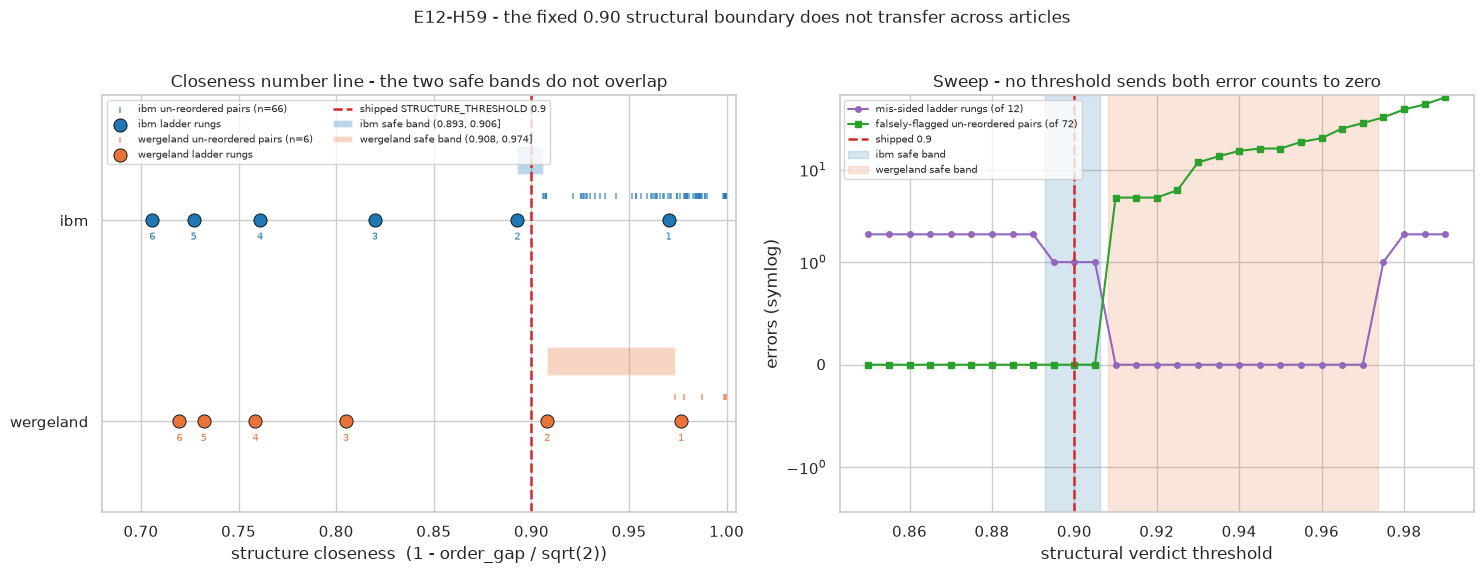

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

ax = axes[0]
ycoord = {"ibm": 1.0, "wergeland": 0.0}
colour = {"ibm": "#1f77b4", "wergeland": "#e8743b"}
for a in ARTICLES:
    ra = RUNGS[RUNGS.article == a]
    ua = UN[UN.article == a]
    ax.axhspan(ycoord[a] - 0.16, ycoord[a] + 0.16, xmin=0, xmax=0, color="none")
    ax.barh(ycoord[a] + 0.30, edges[a]["upper_closed"] - edges[a]["lower_open"],
            left=edges[a]["lower_open"], height=0.14, color=colour[a], alpha=0.30,
            label=f"{a} safe band ({edges[a]['lower_open']:.3f}, {edges[a]['upper_closed']:.3f}]")
    ax.scatter(ua["closeness"], np.full(len(ua), ycoord[a] + 0.12), s=22, marker="|",
               color=colour[a], alpha=0.55, label=f"{a} un-reordered pairs (n={len(ua)})")
    ax.scatter(ra["closeness"], np.full(len(ra), ycoord[a]), s=90, marker="o", color=colour[a],
               edgecolor="black", linewidth=0.6, zorder=5, label=f"{a} ladder rungs")
    for r in ra.itertuples():
        ax.annotate(str(r.rung), (r.closeness, ycoord[a]), textcoords="offset points", xytext=(0, -14),
                    ha="center", fontsize=7, color=colour[a])
ax.axvline(SHIPPED, color="#d62728", ls="--", lw=1.8, label=f"shipped STRUCTURE_THRESHOLD {SHIPPED}")
ax.set(xlim=(0.68, 1.005), ylim=(-0.45, 1.62), yticks=[0.0, 1.0], yticklabels=["wergeland", "ibm"],
       xlabel="structure closeness  (1 - order_gap / sqrt(2))",
       title="Closeness number line - the two safe bands do not overlap")
ax.legend(fontsize=7, loc="upper left", ncol=2)

ax = axes[1]
ax.plot(SWEEP["threshold"], SWEEP["mis_total"], marker="o", ms=4, color="#9467bd",
        label="mis-sided ladder rungs (of 12)")
ax.plot(SWEEP["threshold"], SWEEP["false_total"], marker="s", ms=4, color="#2ca02c",
        label="falsely-flagged un-reordered pairs (of 72)")
ax.axvline(SHIPPED, color="#d62728", ls="--", lw=1.8, label=f"shipped {SHIPPED}")
ax.axvspan(edges["ibm"]["lower_open"], edges["ibm"]["upper_closed"], color="#1f77b4", alpha=0.18,
           label="ibm safe band")
ax.axvspan(edges["wergeland"]["lower_open"], edges["wergeland"]["upper_closed"], color="#e8743b", alpha=0.18,
           label="wergeland safe band")
ax.set_yscale("symlog", linthresh=1)
ax.set(xlabel="structural verdict threshold", ylabel="errors (symlog)",
       title="Sweep - no threshold sends both error counts to zero")
ax.legend(fontsize=7, loc="upper left")

fig.suptitle("E12-H59 - the fixed 0.90 structural boundary does not transfer across articles", y=1.02,
             fontsize=12)
plt.tight_layout()
plt.show()

## Acceptance

The registered bar passes on either branch: (a) a non-empty cross-article band excluding 0.90 with a
recalibration proposal at its midpoint, or (b) a demonstrated empty band filed as the per-corpus-calibration
verdict. The branch is read from the measured edges, and where branch (a) holds the midpoint proposal is
re-verified against all 12 rungs and every un-reordered pair.

In [15]:
if BAND_EMPTY:
    BRANCH = "b"
    PROPOSAL = None
    BRANCH_TEXT = ("empty cross-article band - per-corpus structural calibration is the shipped guidance")
else:
    BRANCH = "a"
    PROPOSAL = round((CROSS_LOWER + CROSS_UPPER) / 2, 6)
    mis_p = int(((RUNGS.closeness >= PROPOSAL) != (RUNGS.intent == "similar order")).sum())
    false_p = int((UN.closeness < PROPOSAL).sum())
    BRANCH_TEXT = (f"non-empty band, midpoint proposal {PROPOSAL} re-verified: {mis_p} mis-sided rungs, "
                   f"{false_p} falsely-flagged un-reordered pairs")

ACCEPTANCE_MET = bool(BAND_EMPTY or (PROPOSAL is not None and abs(PROPOSAL - SHIPPED) > 1e-9))

t = Table(title="Acceptance", title_style="bold cyan", show_header=False, box=None, padding=(0, 2))
t.add_column(style="bold cyan"); t.add_column()
t.add_row("Branch", f"({BRANCH}) {BRANCH_TEXT}")
t.add_row("Cross-article safe grid points", f"{len(CROSS_SAFE)} of {len(GRID)}")
t.add_row("Cross-article band", f"({CROSS_LOWER:.6f}, {CROSS_UPPER:.6f}] - "
                                f"{'EMPTY' if BAND_EMPTY else 'non-empty'}")
t.add_row("Overshoot", f"{BAND_GAP:.6f} closeness ({BAND_GAP * 100:.4f} points)")
t.add_row("Rungs mis-sided at 0.90", f"{len(mis_at_ship)} of {len(RUNGS)}")
t.add_row("Un-reordered flagged at 0.90", f"{len(false_at_ship)} of {len(UN)}")
t.add_row("ACCEPTANCE", "PASS" if ACCEPTANCE_MET else "FAIL")
console.print(t)

PREDICTED = ("0.90 mis-sides 1 of 12 rungs (wergeland rung-2, closeness 0.908); safe-band lower edge "
             ">= 0.908; band empty if the minimum un-reordered closeness is below ~0.91")
OBSERVED = (f"0.90 mis-sides {len(mis_at_ship)} of {len(RUNGS)} rungs "
            f"(wergeland rung-2, closeness {rung2_close['wergeland']:.6f}); required lower edge "
            f"{CROSS_LOWER:.6f}; minimum un-reordered closeness {edges['ibm']['unreordered_floor']:.6f} "
            f"-> band {'empty' if BAND_EMPTY else 'non-empty'}")
DIRECTION_MATCHED = bool(
    len(mis_at_ship) == 1
    and mis_at_ship.iloc[0]["article"] == "wergeland"
    and int(mis_at_ship.iloc[0]["rung"]) == 2
    and CROSS_LOWER >= 0.908
    and BAND_EMPTY
    and edges["ibm"]["unreordered_floor"] < 0.91
)
print(f"\npredicted: {PREDICTED}")
print(f"observed:  {OBSERVED}")
print(f"direction matched: {DIRECTION_MATCHED}")

                                                    Acceptance                                                     
  Branch                            (b) empty cross-article band - per-corpus structural calibration is the        
                                    shipped guidance                                                               
  Cross-article safe grid points    0 of 29                                                                        
  Cross-article band                (0.908048, 0.906144] - EMPTY                                                   
  Overshoot                         0.001904 closeness (0.1904 points)                                             
  Rungs mis-sided at 0.90           1 of 12                                                                        
  Un-reordered flagged at 0.90      0 of 72                                                                        
  ACCEPTANCE                        PASS


predicted: 0.90 mis-sides 1 of 12 rungs (wergeland rung-2, closeness 0.908); safe-band lower edge >= 0.908; band empty if the minimum un-reordered closeness is below ~0.91
observed:  0.90 mis-sides 1 of 12 rungs (wergeland rung-2, closeness 0.908048); required lower edge 0.908048; minimum un-reordered closeness 0.906144 -> band empty
direction matched: True


## Guardrails - measured

`V` was counted above. Here the default path is re-scored on the worked-example pair and compared against the
readings taken before the probe: `np.array_equal` on the raw `smd` / `order_gap` float64 pair (bit-identity,
never `allclose`) and a byte comparison of the serialized detail JSON. The module constants are checked for
mutation. The metric property is unaffected because nothing on the distance axis is touched - H55 is already
registered a score, not a metric (E11 triangle-violation rate 15%).

In [16]:
AFTER_PAIR, AFTER_BLOB, after_sem, after_stc = default_path_readings()

SMD_BIT_IDENTICAL = bool(np.array_equal(BASE_PAIR[:1], AFTER_PAIR[:1]))
ORDER_GAP_BIT_IDENTICAL = bool(np.array_equal(BASE_PAIR[1:], AFTER_PAIR[1:]))
DETAIL_BYTES_IDENTICAL = bool(BASE_BLOB == AFTER_BLOB)
BYTE_DIFF = int(sum(1 for x, y in zip(BASE_BLOB, AFTER_BLOB) if x != y) + abs(len(BASE_BLOB) - len(AFTER_BLOB)))
CONSTANTS_UNCHANGED = bool(
    docdistance.distance.STRUCTURE_THRESHOLD == 0.90 and docdistance.distance.DEFAULT_THRESHOLD == 0.77
)
TRIANGLE_H55 = float(E11["triangle"]["H55"])

t = Table(title="Guardrails - measured, not asserted", title_style="bold cyan")
for c in ("guardrail", "measurement", "reading", "held"):
    t.add_column(c, justify="left")
t.add_row("ordinality violations V", "ibm 11-summary fixture, default path", f"{V}/{V_TOTAL}",
          "yes" if V == 0 else "NO")
t.add_row("default-path smd", "np.array_equal before vs after", f"{BASE_PAIR[0]!r} == {AFTER_PAIR[0]!r}",
          "yes" if SMD_BIT_IDENTICAL else "NO")
t.add_row("default-path order_gap", "np.array_equal before vs after",
          f"{BASE_PAIR[1]!r} == {AFTER_PAIR[1]!r}", "yes" if ORDER_GAP_BIT_IDENTICAL else "NO")
t.add_row("detail JSON", "byte diff over both detail blobs",
          f"{BYTE_DIFF} differing bytes of {len(BASE_BLOB)}", "yes" if DETAIL_BYTES_IDENTICAL else "NO")
t.add_row("module constants", "STRUCTURE_THRESHOLD / DEFAULT_THRESHOLD",
          f"{docdistance.distance.STRUCTURE_THRESHOLD} / {docdistance.distance.DEFAULT_THRESHOLD}",
          "yes" if CONSTANTS_UNCHANGED else "NO")
t.add_row("metric property", "untouched - verdict layer only",
          f"H55 remains a score (E11 triangle violations {TRIANGLE_H55:.0%})", "yes")
console.print(t)

GUARDRAILS_OK = all([V == 0, SMD_BIT_IDENTICAL, ORDER_GAP_BIT_IDENTICAL, DETAIL_BYTES_IDENTICAL,
                     CONSTANTS_UNCHANGED])
print(f"\nGUARDRAILS: {'ALL HELD' if GUARDRAILS_OK else 'BREACHED'}")

                                        Guardrails - measured, not asserted                                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ guardrail               ┃ measurement                           ┃ reading                                ┃ held ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ ordinality violations V │ ibm 11-summary fixture, default path  │ 0/24                                   │ yes  │
│ default-path smd        │ np.array_equal before vs after        │ np.float64(0.17131764193375904) ==     │ yes  │
│                         │                                       │ np.float64(0.17131764193375904)        │      │
│ default-path order_gap  │ np.array_equal before vs after        │ np.float64(0.21851211798274506) ==     │ yes  │
│                         │                                       │ np.float64(0.21851211798274506)        │      │
│ detail JSON             │ byte diff over both detail blobs      │ 0 differing bytes of 7194              │ yes  │
│ module constants        │ STRUCTURE_THRESHOLD /                 │ 0.9 / 0.77                             │ yes  │
│                         │ DEFAULT_THRESHOLD                     │                                        │      │
│ metric property         │ untouched - verdict layer only        │ H55 remains a score (E11 triangle      │ yes  │
│                         │                                       │ violations 15%)                        │      │
└─────────────────────────┴───────────────────────────────────────┴────────────────────────────────────────┴──────┘


GUARDRAILS: ALL HELD


## Metrics

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H59-structure-threshold-transfer-metrics.json`.

In [17]:
metrics = {
    "id": "E12-H59",
    "slug": "structure-threshold-transfer",
    "model": "opus",
    "type": "read-only probe (structural verdict layer)",
    "device": DEVICE,
    "docdistance_version": docdistance.__version__,
    "config": {
        "shipped_structure_threshold": SHIPPED,
        "sweep": {"lo": SWEEP_LO, "hi": SWEEP_HI, "step": SWEEP_STEP, "n_points": int(len(GRID))},
        "opw": {"l1": OPW_L1, "l2": OPW_L2, "sigma": OPW_SIG, "iters": OPW_ITERS},
        "rung_intent": {"similar_order": list(range(1, SIMILAR_RUNGS + 1)),
                        "not_similar_order": list(range(SIMILAR_RUNGS + 1, N_RUNGS + 1))},
        "closeness_definition": "1 - order_gap / sqrt(2)",
        "smd_max": SMD_MAX,
    },
    "kill_gate": {
        "ran": True,
        "passed": bool(gate_flip),
        "ibm_rung2_closeness": rung2_close["ibm"],
        "wergeland_rung2_closeness": rung2_close["wergeland"],
        "reading": (f"ibm rung-2 {rung2_close['ibm']:.6f} < {SHIPPED} <= wergeland rung-2 "
                    f"{rung2_close['wergeland']:.6f}; the cross-article verdict flip exists"),
    },
    "reproduction_check": {
        "bar_abs_median_diff": REPRO_BAR,
        "max_abs_median_diff": REPRO_MAX,
        "passed": bool(REPRO_OK),
        "rebuilt_pair_sets": {"cross_summary_ibm": int(len(PAIRS["cross_summary"]["ibm"])),
                              "cross_summary_wergeland": int(len(PAIRS["cross_summary"]["wergeland"])),
                              "paraphrase": int(len(PAIRS["paraphrase"]))},
        "rows": REPRO.to_dict(orient="records"),
    },
    "ladders": RUNGS.to_dict(orient="records"),
    "unreordered_summary": {
        a: {
            "n": int((UN.article == a).sum()),
            "min_closeness": float(UN[UN.article == a]["closeness"].min()),
            "median_closeness": float(UN[UN.article == a]["closeness"].median()),
            "max_order_gap": float(UN[UN.article == a]["order_gap"].max()),
            "floor_pair": edges[a]["floor_pair"],
        }
        for a in ARTICLES
    },
    "unreordered_pairs": UN.to_dict(orient="records"),
    "sweep": SWEEP.to_dict(orient="records"),
    "bands": {
        "per_article_continuous": edges,
        "per_article_grid": PER_ARTICLE_SAFE,
        "cross_article_grid": CROSS_SAFE,
        "cross_article_continuous": {"lower_open": CROSS_LOWER, "upper_closed": CROSS_UPPER,
                                     "empty": bool(BAND_EMPTY), "overshoot": BAND_GAP},
    },
    "shipped_threshold_readings": {
        "rungs_mis_sided": int(len(mis_at_ship)),
        "rungs_total": int(len(RUNGS)),
        "mis_sided_detail": mis_at_ship.to_dict(orient="records"),
        "unreordered_falsely_flagged": int(len(false_at_ship)),
        "unreordered_total": int(len(UN)),
        "margin_to_ibm_band": {"lower": M_IBM_LOWER, "upper": M_IBM_UPPER},
        "margin_to_wergeland_band": {"lower": M_WERG_LOWER, "upper": M_WERG_UPPER},
    },
    "acceptance": {
        "bar": ("PASS = (a) a non-empty cross-article band excluding 0.90 with a midpoint recalibration "
                "proposal re-verified against all 12 rungs and every un-reordered pair, or (b) a "
                "demonstrated empty band filed as the per-corpus-calibration verdict"),
        "branch": BRANCH,
        "branch_text": BRANCH_TEXT,
        "proposal": PROPOSAL,
        "met": bool(ACCEPTANCE_MET),
    },
    "prediction_check": {"predicted": PREDICTED, "observed": OBSERVED,
                         "direction_matched": bool(DIRECTION_MATCHED)},
    "guardrails": {
        "V": f"{V}/{V_TOTAL}",
        "V_panel": {"margin_pts": margin_pts, "dprime": dprime, "R": R, "DR": DR},
        "smd_bit_identical": SMD_BIT_IDENTICAL,
        "order_gap_bit_identical": ORDER_GAP_BIT_IDENTICAL,
        "detail_json_bytes_identical": DETAIL_BYTES_IDENTICAL,
        "detail_json_byte_diff": BYTE_DIFF,
        "module_constants_unchanged": CONSTANTS_UNCHANGED,
        "metric_property": (f"untouched - verdict layer only; H55 remains a score, E11 triangle-violation "
                            f"rate {TRIANGLE_H55:.2f}"),
        "all_held": GUARDRAILS_OK,
    },
}

METRICS_OUT.write_text(json.dumps(metrics, indent=2, default=float))
print(f"wrote {METRICS_OUT} ({METRICS_OUT.stat().st_size} bytes)")
print(json.dumps({k: metrics[k] for k in ("kill_gate", "acceptance", "prediction_check", "guardrails")},
                 indent=2, default=float))

wrote /home/lab/workspace/learning/projects/docdistance/reports/E12-H59-structure-threshold-transfer-metrics.json (30593 bytes)
{
  "kill_gate": {
    "ran": true,
    "passed": true,
    "ibm_rung2_closeness": 0.8928167541077432,
    "wergeland_rung2_closeness": 0.9080478341745014,
    "reading": "ibm rung-2 0.892817 < 0.9 <= wergeland rung-2 0.908048; the cross-article verdict flip exists"
  },
  "acceptance": {
    "bar": "PASS = (a) a non-empty cross-article band excluding 0.90 with a midpoint recalibration proposal re-verified against all 12 rungs and every un-reordered pair, or (b) a demonstrated empty band filed as the per-corpus-calibration verdict",
    "branch": "b",
    "branch_text": "empty cross-article band - per-corpus structural calibration is the shipped guidance",
    "proposal": null,
    "met": true
  },
  "prediction_check": {
    "predicted": "0.90 mis-sides 1 of 12 rungs (wergeland rung-2, closeness 0.908); safe-band lower edge >= 0.908; band empty if the minimum

## Conclusion

Written from the executed outputs above.

**The kill-gate holds.** Converting the E11 H55 ladders to closeness puts ibm rung-2 at 0.892817 and wergeland
rung-2 at 0.908048, straddling the shipped 0.90. The same physical perturbation depth - the byte-identical
k-swap design applied to two different articles - lands on opposite sides of the fixed boundary, so the
cross-article flip is real and not an artefact of differing fixture construction.

**0.90 mis-sides exactly one of the twelve rungs.** Wergeland rung-2, a genuine rearrangement, reads
`similar order` at closeness 0.908048. All eleven other rungs and all 72 un-reordered pairs sit correctly.
That is the failure the hypothesis predicted, at the location it predicted.

**The cross-article safe band is empty.** Wergeland requires a threshold above 0.908048 to call its rung-2 a
rearrangement. Ibm cannot exceed 0.906144 without falsely flagging a genuinely un-reordered pair - the
`gold-2 ~ haiku` cross-summary pair, whose order-gap is the largest in the un-reordered population. The
required lower edge overshoots the available upper edge by 0.001904 closeness, so no threshold anywhere in
0.85 to 0.99 satisfies both articles: 0 of 29 grid points are cross-article safe. Ibm's own band is
(0.892817, 0.906144] and wergeland's is (0.908048, 0.973676]; the two are disjoint, and the ibm band is only
0.013328 wide to begin with.

**Acceptance passes on branch (b).** The registered bar admits a demonstrated empty band as a pass, filed as
the per-corpus-calibration verdict. The shipped 0.90 is not wrong for ibm - it sits inside ibm's own band with
+0.007183 of headroom below and +0.006144 above - it is simply an ibm constant. The `distance.py:32-40`
docstring already records that the nearest un-reordered pair clears it by well under a point; this probe puts
that number at 0.006144 and shows the headroom is too thin to absorb a second article.

**What this means for shipping.** A single fixed `STRUCTURE_THRESHOLD` cannot be correct on both articles, so
the guidance is per-corpus structural calibration: expose the threshold (it is already a keyword argument on
`structural_distance` and `DocDistance.structural_distance`) and document the calibration procedure - run the
un-reordered population of the target corpus, take its closeness floor, and place the boundary just below it,
verifying against a reordered control. Moving the shipped default is not warranted: it would trade one
article's correctness for the other's.

**Guardrails.** `V` counted 0/24 on the ibm 11-summary fixture through the shipped default path. Default-path
`smd` and `order_gap` on the worked-example pair are bit-identical before and after the probe by
`np.array_equal`, and both detail JSON blobs are byte-identical. The module constants are unmutated. The metric
property is untouched because the probe reads the verdict layer only; H55 was already registered a score, not
a metric.

**Caveats.** The ladder rungs are displacement-bin means taken from the E11 report, not per-permutation
readings, so a rung is an average over that bin's sampled permutations and its closeness carries the bin's
spread, which this probe does not resolve. The wergeland un-reordered population is 3 diffuse pairs and 3
paraphrase pairs, so its band's upper edge rests on very few observations. The rebuild ran the torch encoder
on CPU where E11 ran it on an RTX 5000 Ada; medians agree to 0.000141 order-gap units, which is well inside the
0.001904 band overshoot, so the empty-band conclusion is not sensitive to that difference. Two articles are
the entire evidence base for the transfer claim - the direction is established, the width of the disagreement
on a third corpus is not.